In [8]:
# from matplotlib_venn import venn2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os

In [9]:
# initialize dataFrames
def initialize_dfs(names):
    return {name: pd.DataFrame() for name in names}
    
# function to read csv files into dataframes
def read_csv_files(names, df_dict, base_path, columns):
    for name in names:
        file_path = os.path.join(base_path, name, "produce_final_form/final_form.csv")
        df_dict[name] = pd.read_csv(file_path, sep=',', usecols=columns)

# Filter conditions: mirBase, linearfold, mirdeep2
def filter_dataframes(names, df_source, df_with_match):
    for name in names:
        df_with_match[name] = filter_any_condition_met(df_source[name])
        # df_all_zero[name] = filter_none_met(df_source[name])

def filter_any_condition_met(df):
    filtered_df = df[(df[['mirBase', 'linearfold', 'mirdeep2']].sum(axis=1) > 0)]
    #filtered_df = filtered_df.loc[:, ['sequence']]
    filtered_df = filtered_df.loc[:, ['sequence', 'qseqid_count']]
    # print("filtered_df",filtered_df)
    return filtered_df

# def filter_none_met(df):
#     filtered_df = df[(df[['mirBase', 'linearfold', 'mirdeep2']].sum(axis=1) == 0)]
#     filtered_df = filtered_df.loc[:, ['sequence']]
#     # filtered_df = filtered_df.loc[:, ['sequence', 'umi_count']]
#     # print("filtered_df_none",filtered_df)
#     return filtered_df

def merge_seqid_count(df, result_df, column_name):
    result_df = result_df.merge(df, on='sequence', how='left').fillna(0)
    result_df = result_df.rename(columns={'qseqid_count': column_name})
    return result_df

# function to generate form and save the result
def generate_and_save_result(names, df_dict):
    all_sequences = pd.concat([df_dict[name]['sequence'] for name in names]).unique()
    result_df = pd.DataFrame({'sequence': all_sequences})
    
    for name in names:
        df = df_dict[name]
        result_df = merge_seqid_count(df, result_df, f'{name}')
    print("result_df",result_df)
    return result_df

In [10]:
# define the base path for output csv files
base_path = "../../../../3rd_3samples_output"

# names corresponding to the file names for normal and control
#first three is total group, second line is control group
total_names = [
    "SRR20723831", "SRR20723832", "SRR20723833"
]


# columns to read from the original CSV files
read_columns = ['sequence', 'mirBase', 'linearfold', 'mirdeep2','qseqid_count']


df_total = initialize_dfs(total_names)
df_total_with_match = initialize_dfs(total_names)


read_csv_files(total_names, df_total, base_path, read_columns)


filter_dataframes(total_names, df_total, df_total_with_match)
for name in total_names:
    num_rows = len(df_total_with_match[name])
    print(f"DataFrame {name} has {num_rows} lines.")

print(df_total_with_match)


result_df = generate_and_save_result(total_names, df_total_with_match)
result_df['total_share_count'] = result_df['SRR20723831'] + result_df['SRR20723832'] + result_df['SRR20723833']

# Sort by 'Total' from largest to smallest
df_sorted = result_df.sort_values(by='total_share_count', ascending=False)
print(df_sorted.head(10))


DataFrame SRR20723831 has 1873660 lines.
DataFrame SRR20723832 has 1793252 lines.
DataFrame SRR20723833 has 1952763 lines.
{'SRR20723831':                          sequence  qseqid_count
0        GGAAAAGTAGGACACCGCCGAACA         26993
1          ATGTCAAGTAGTTGCTCGTAGT          1194
2         GAAAAGTAGGACACCGCCGAACA        153528
4             CCCGGGCCTTGTACACACC           603
6         CCTGGTGAAGTGGGGTTCTGGTG            54
...                           ...           ...
2560753     GCCAACGGGCCGGTGCTCTCG             1
2560755       AGGTGAAGGAGAATACATG             1
2560756       CTGCAGAGCCTGGGCGGTC             1
2560757        ATCTGCCACCGGTCAACC             1
2560758     TTTGGTGACGGAAACGCTGAC             1

[1873660 rows x 2 columns], 'SRR20723832':                         sequence  qseqid_count
0            CAAGGATGTCGGGTAAGCC             1
1        CTACCGCCTTCGGGCAGATCCTC        438486
2           GAAATGACGCAATGACCTCT         46386
3            CTTCGGGCAGATCCTCATC          9469
4     

In [11]:
final_df = df_sorted.head(10)


aaa
[1140043.0, 586914.0, 538377.0, 313165.0, 179121.0, 189925.0, 153528.0, 122046.0, 122933.0, 108531.0]
[1463605.0, 624360.0, 438486.0, 354973.0, 189500.0, 156183.0, 145404.0, 98583.0, 120708.0, 113845.0]
[1227388.0, 628729.0, 370960.0, 510850.0, 284839.0, 180621.0, 174449.0, 124534.0, 61886.0, 14374.0]


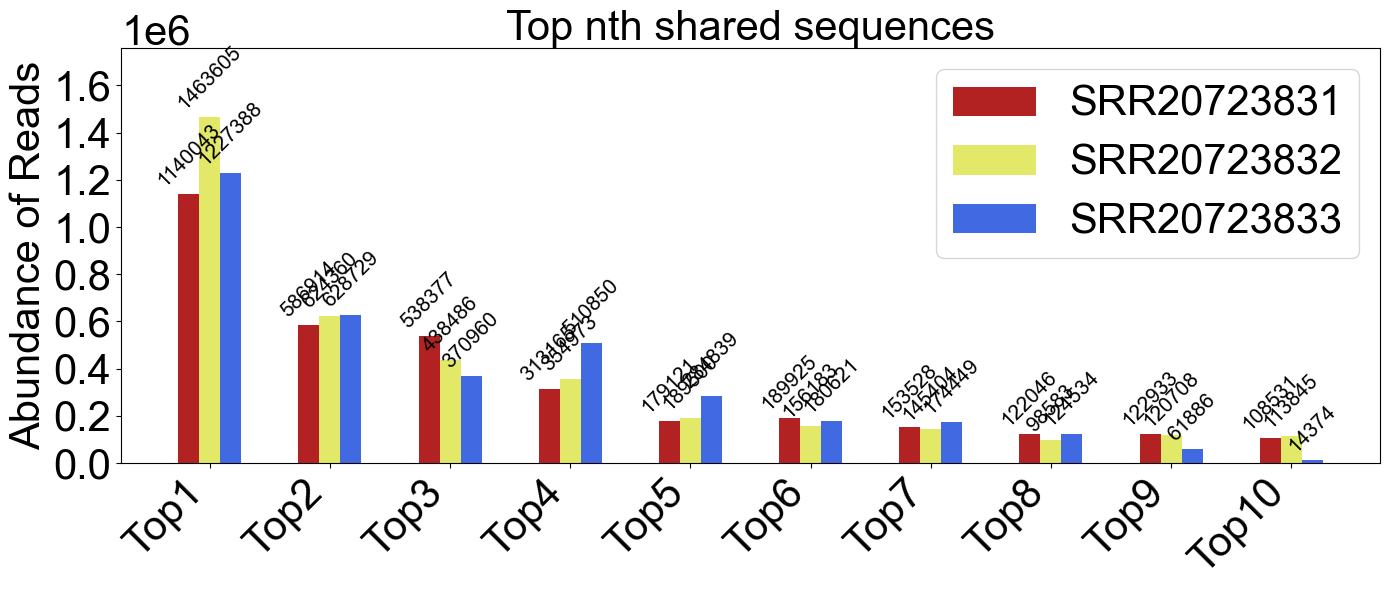

In [38]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

fm.fontManager.addfont(str("arial.ttf"))


arial_font = fm.FontProperties(fname="arial.ttf", size=30)

arial_font_in = fm.FontProperties(fname="arial.ttf", size=15)
print("aaa")

labels = ["Top1", "Top2", "Top3", "Top4", "Top5","Top6","Top7","Top8","Top9","Top10"]


sample_31 = final_df['SRR20723831'].tolist()
sample_32 = final_df['SRR20723832'].tolist()
sample_33 = final_df['SRR20723833'].tolist()
print(sample_31)
print(sample_32)
print(sample_33)


x = np.arange(len(labels))
width = 0.35  # width of the bars


fig, ax = plt.subplots(figsize=(14, 6))
# bars1 = ax.bar(x - width/2, sample_31, width/2, label='SRR20723831', color='#1f77b4')
# bars2 = ax.bar(x, sample_32, width/2, label='SRR20723832', color='#ff7f0e')
# bars3 = ax.bar(x + width/2, sample_33, width/2, label='SRR20723833', color='#2ca02c')

bars1 = ax.bar(x - width/2, sample_31, width/2, label='SRR20723831', color='firebrick')
bars2 = ax.bar(x, sample_32, width/2, label='SRR20723832', color='#E2E867')
bars3 = ax.bar(x + width/2, sample_33, width/2, label='SRR20723833', color='royalblue')

# bars1 = ax.bar(x - width/2, sample_31, width/2, label='SRR20723831', color='#99cc99')
# bars2 = ax.bar(x, sample_32, width/2, label='SRR20723832', color='#E2E867')
# bars3 = ax.bar(x + width/2, sample_33, width/2, label='SRR20723833', color='#ccccff')
all_heights = sample_31 + sample_32 + sample_33
max_height = max(all_heights)


ax.set_ylim(0, max_height * 1.2)

ax.set_ylabel('Abundance of Reads', fontproperties=arial_font)
ax.set_title('Top nth shared sequences', fontproperties=arial_font)


ax.set_xticks(x)
ax.set_xticklabels(labels, fontproperties=arial_font, rotation=45, ha="right")
for label in ax.get_yticklabels():
    label.set_fontproperties(arial_font)
offset_text = ax.yaxis.get_offset_text()
offset_text.set_fontproperties(arial_font)

ax.legend(prop=arial_font, title_fontproperties=arial_font)

for bar in bars1 + bars2 + bars3:
    height = bar.get_height()
    if height > 0:
        ax.annotate(f'{int(height)}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),  
                    textcoords="offset points",
                    ha='center', va='bottom', rotation=45, fontproperties=arial_font_in)


plt.tight_layout()

# plt.xticks(fontproperties=arial_font)
plt.savefig("figure4_D.pdf", format="pdf", bbox_inches="tight")
plt.show()
# plt.savefig(os.path.join(code_path, "5th_samples_after_all_step_length_plot.png") , format='png', dpi=300, bbox_inches='tight')
plt.close() 
